# P-1 Anomaly Visualization and Correlation Exploration

This standalone notebook is for exploratory analysis of the NASA/JPL **P-1** channel.

It includes:
- the full P-1 telemetry series with labeled anomaly intervals,
- zoomed plots around each anomaly,
- context/command activity around each anomaly,
- telemetry autocorrelation,
- telemetry–context correlations,
- lagged context–telemetry correlations,
- context–context correlations,
- anomaly-vs-normal context activity.

The anomaly labels are used here for **exploration only**, not for tuning the forecasting models or Telemanom detector.


In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root():
    cwd = Path.cwd().resolve()
    candidates = [cwd] + list(cwd.parents[:4])
    for candidate in candidates:
        if (candidate / "data" / "data" / "test" / "P-1.npy").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find data/data/test/P-1.npy. "
        "Run this notebook from the project repository or a subfolder."
    )

repo_dir = find_repo_root()
data_dir = repo_dir / "data" / "data"

print("Repository root:", repo_dir)
print("Data directory:", data_dir)


Repository root: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors
Data directory: /Users/jezercahodaj/Desktop/Erdos-Project copy/fall-2026-spacecraft-sensors/data/data


In [2]:
p1_train = np.load(data_dir / "train" / "P-1.npy")
p1_test = np.load(data_dir / "test" / "P-1.npy")

labels = pd.read_csv(data_dir / "labeled_anomalies.csv")
p1_row = labels.loc[labels["chan_id"] == "P-1"].iloc[0]

p1_intervals = sorted(
    [tuple(x) for x in ast.literal_eval(p1_row["anomaly_sequences"])]
)

train_signal = p1_train[:, 0]
test_signal = p1_test[:, 0]

train_context = p1_train[:, 1:]
test_context = p1_test[:, 1:]

context_names = [
    f"context_{j}"
    for j in range(1, train_context.shape[1] + 1)
]

p1_truth = np.zeros(len(test_signal), dtype=bool)
for start, end in p1_intervals:
    p1_truth[start:end + 1] = True

print("Training shape:", p1_train.shape)
print("Test shape:", p1_test.shape)
print("Labeled intervals:", p1_intervals)
print("Total labeled anomaly observations:", p1_truth.sum())


Training shape: (2872, 25)
Test shape: (8505, 25)
Labeled intervals: [(2149, 2349), (3539, 3779), (4536, 4844)]
Total labeled anomaly observations: 751


## 1. Full P-1 telemetry with labeled anomaly intervals

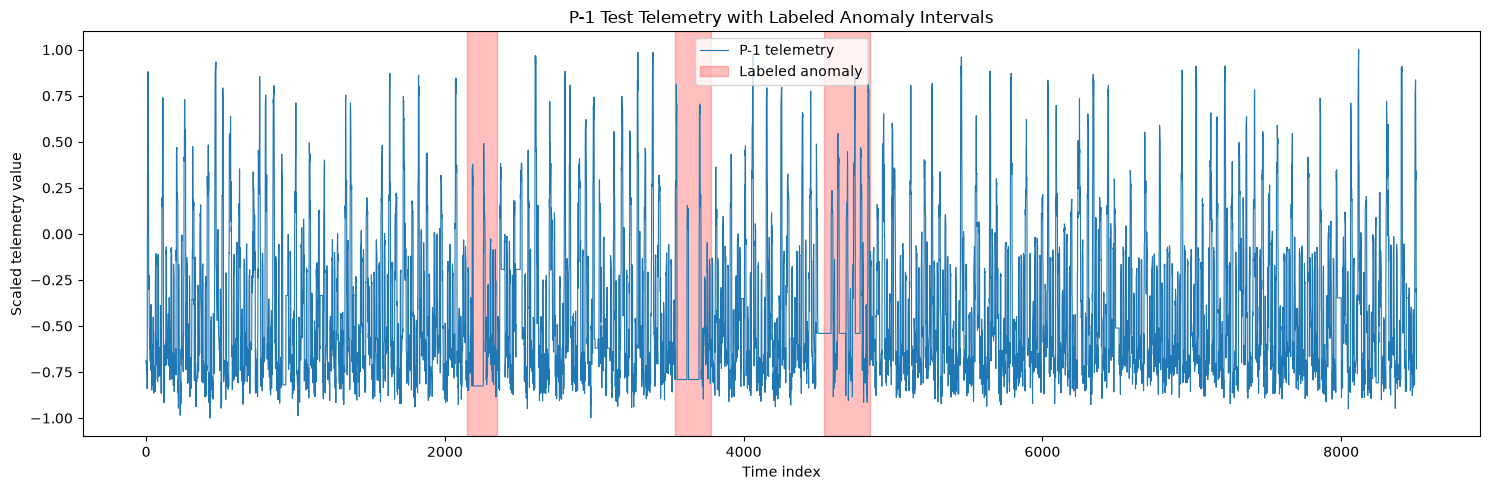

In [13]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    np.arange(len(test_signal)),
    test_signal,
    linewidth=0.8,
    label="P-1 telemetry"
)

for i, (start, end) in enumerate(p1_intervals):
    ax.axvspan(
        start,
        end,
        color = "red",
        alpha=0.25,
        label="Labeled anomaly" if i == 0 else None
    )

ax.set(
    title="P-1 Test Telemetry with Labeled Anomaly Intervals",
    xlabel="Time index",
    ylabel="Scaled telemetry value"
)

ax.legend()
plt.tight_layout()
plt.show()


## 2. Zoom in around each anomaly

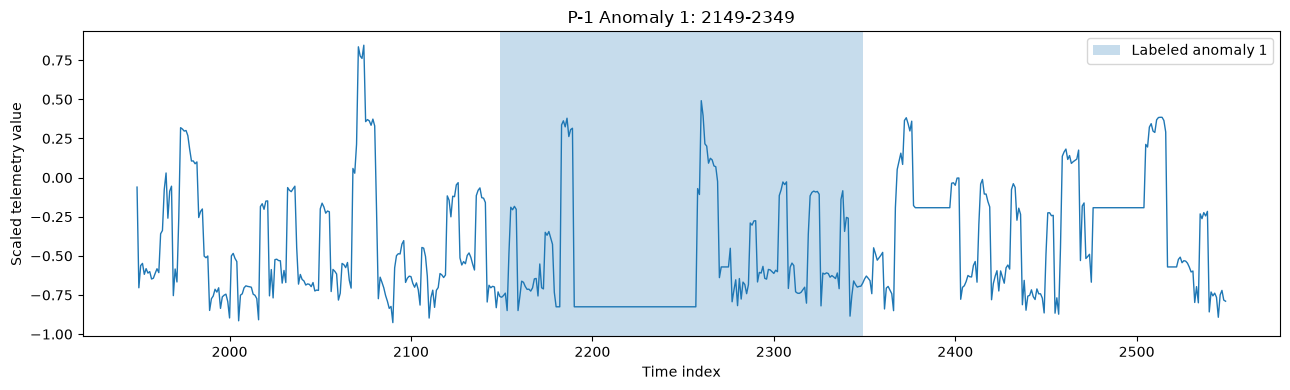

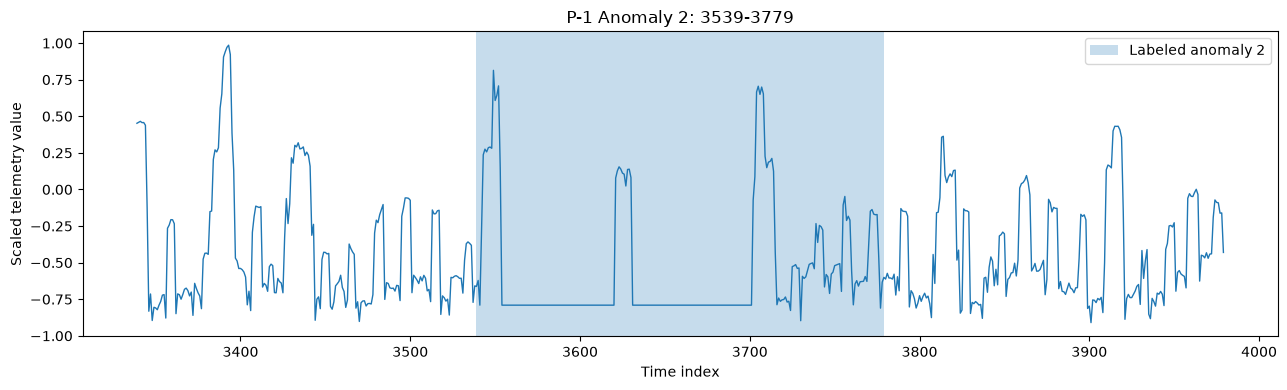

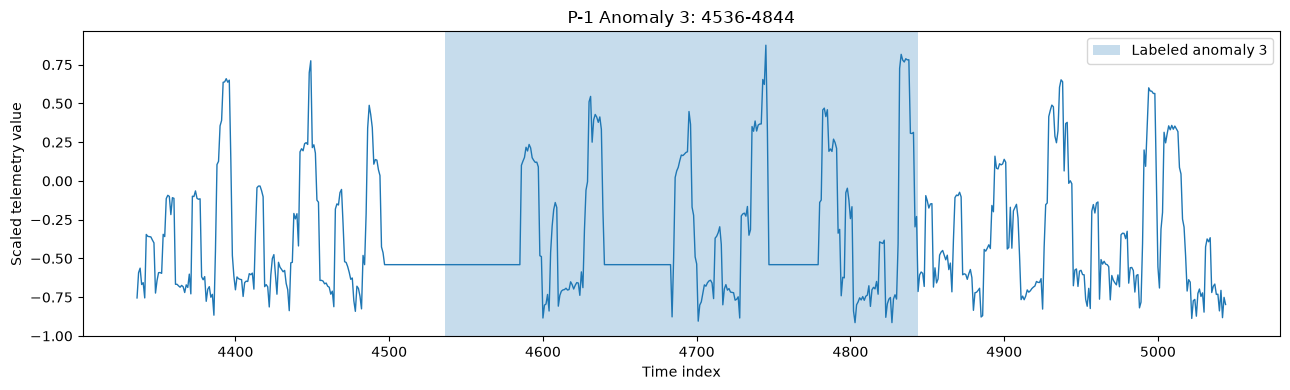

In [4]:
PADDING = 200

for event_number, (start, end) in enumerate(p1_intervals, start=1):
    plot_start = max(0, start - PADDING)
    plot_end = min(len(test_signal) - 1, end + PADDING)

    fig, ax = plt.subplots(figsize=(13, 4))

    indices = np.arange(plot_start, plot_end + 1)

    ax.plot(
        indices,
        test_signal[plot_start:plot_end + 1],
        linewidth=1
    )

    ax.axvspan(
        start,
        end,
        alpha=0.25,
        label=f"Labeled anomaly {event_number}"
    )

    ax.set(
        title=f"P-1 Anomaly {event_number}: {start}-{end}",
        xlabel="Time index",
        ylabel="Scaled telemetry value"
    )

    ax.legend()
    plt.tight_layout()
    plt.show()


## 3. Context activity around each anomaly

Rows are context variables and columns are time. The two vertical lines mark the labeled anomaly boundaries.


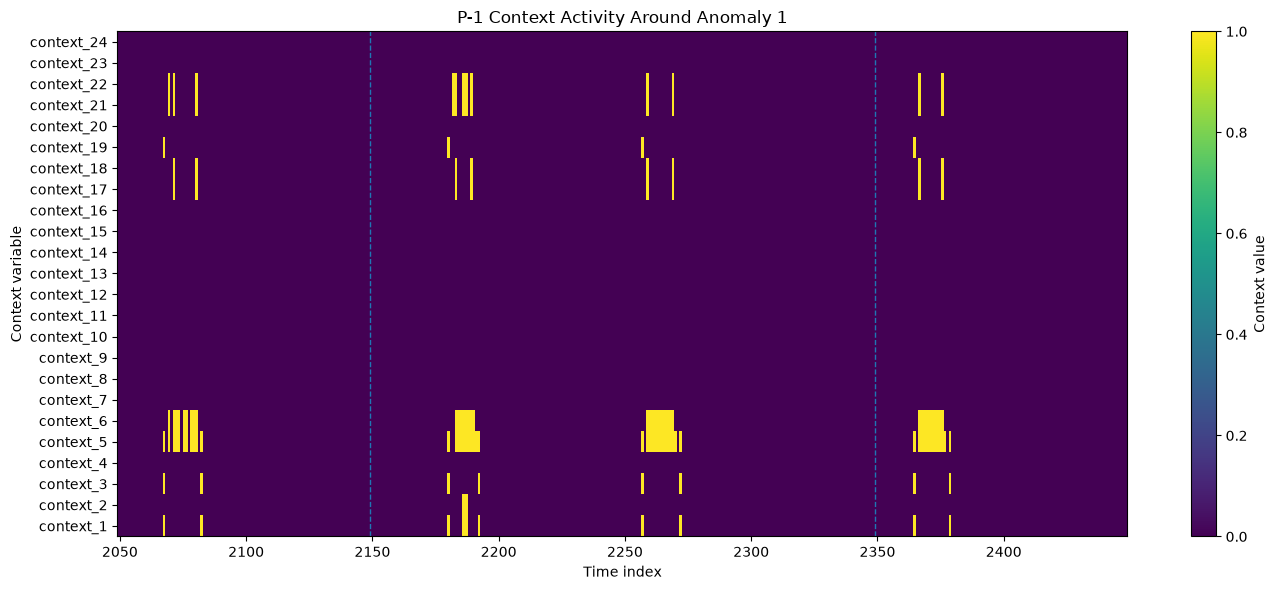

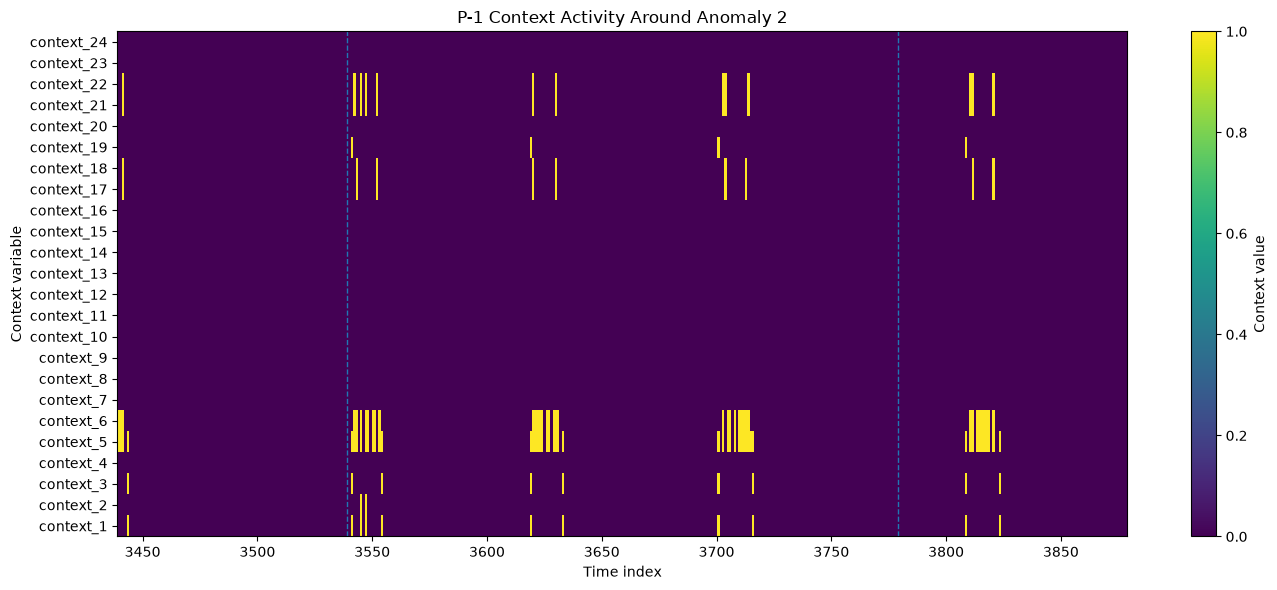

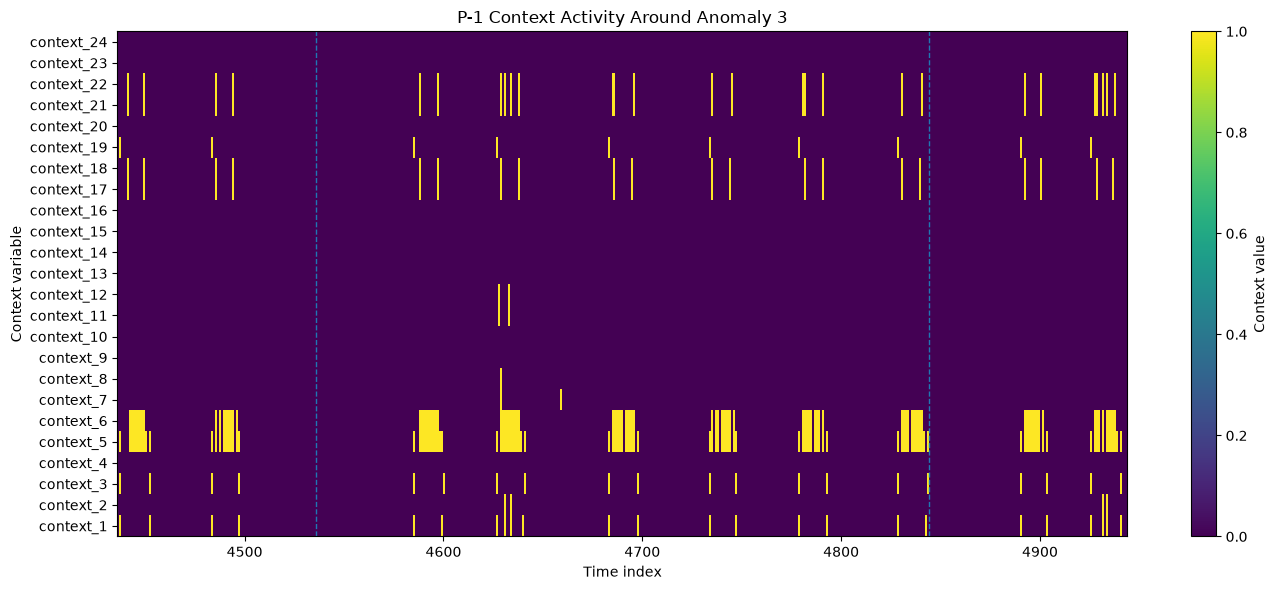

In [5]:
CONTEXT_PADDING = 100

for event_number, (start, end) in enumerate(p1_intervals, start=1):
    plot_start = max(0, start - CONTEXT_PADDING)
    plot_end = min(len(test_signal) - 1, end + CONTEXT_PADDING)

    window = test_context[plot_start:plot_end + 1, :].T

    fig, ax = plt.subplots(figsize=(14, 6))

    image = ax.imshow(
        window,
        aspect="auto",
        interpolation="nearest",
        origin="lower",
        extent=[
            plot_start,
            plot_end,
            0.5,
            len(context_names) + 0.5
        ]
    )

    ax.axvline(start, linestyle="--", linewidth=1)
    ax.axvline(end, linestyle="--", linewidth=1)

    ax.set(
        title=f"P-1 Context Activity Around Anomaly {event_number}",
        xlabel="Time index",
        ylabel="Context variable"
    )

    ax.set_yticks(np.arange(1, len(context_names) + 1))
    ax.set_yticklabels(context_names)

    fig.colorbar(image, ax=ax, label="Context value")
    plt.tight_layout()
    plt.show()


# Correlations worth exploring

The most useful correlation questions for this project are:

1. **Telemetry autocorrelation**: how strongly does current telemetry relate to its own past?
2. **Telemetry–context correlation**: which context variables are associated with telemetry level?
3. **Lagged context–telemetry correlation**: does a context variable at time \(t-k\) relate to telemetry at time \(t\)?
4. **Context–context correlation**: which context variables are redundant with one another?
5. **Anomaly vs normal context activity**: do some contexts occur more often during labeled anomaly intervals?

Because P-1 anomalies are contextual, raw correlation between telemetry and the anomaly flag is not expected to be the most informative quantity.


## 4. Telemetry autocorrelation

,lag,correlation
0,1,0.864775
1,2,0.743903
2,3,0.595948
3,4,0.446024
4,5,0.312451
5,6,0.215934
6,7,0.132522
7,8,0.053797
8,9,-0.021261
9,10,-0.083481


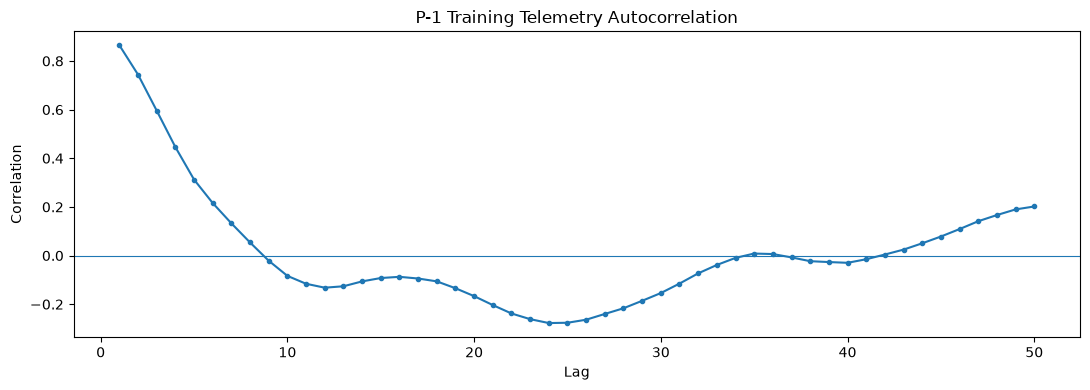

In [6]:
MAX_AUTOCORR_LAG = 50

autocorr_df = pd.DataFrame({
    "lag": np.arange(1, MAX_AUTOCORR_LAG + 1)
})

autocorr_df["correlation"] = [
    pd.Series(train_signal).autocorr(lag=lag)
    for lag in autocorr_df["lag"]
]

display(autocorr_df)

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    autocorr_df["lag"],
    autocorr_df["correlation"],
    marker="o",
    markersize=3
)

ax.axhline(0, linewidth=0.8)

ax.set(
    title="P-1 Training Telemetry Autocorrelation",
    xlabel="Lag",
    ylabel="Correlation"
)

plt.tight_layout()
plt.show()


## 5. Telemetry–context correlations

For binary context variables, Pearson correlation with telemetry is numerically equivalent to point-biserial correlation.

Constant context variables are excluded because their correlation is undefined.


,context,correlation,absolute_correlation
0,context_6,0.663332,0.663332
1,context_5,0.602789,0.602789
2,context_22,0.269912,0.269912
3,context_21,0.269460,0.269460
4,context_17,0.255216,0.255216
5,context_18,0.253711,0.253711
6,context_2,0.140434,0.140434
7,context_19,-0.053073,0.053073
8,context_13,0.052659,0.052659
9,context_14,0.052659,0.052659


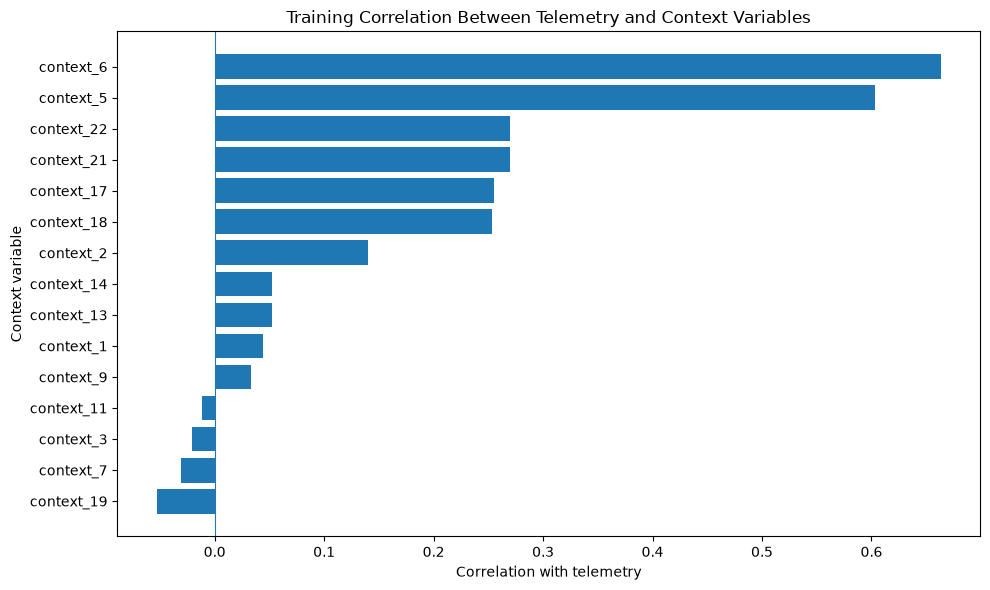

In [7]:
context_std = train_context.std(axis=0)
nonconstant_mask = context_std > 0

nonconstant_names = np.array(context_names)[nonconstant_mask]
nonconstant_train_context = train_context[:, nonconstant_mask]

rows = []

for j, name in enumerate(nonconstant_names):
    corr = np.corrcoef(
        train_signal,
        nonconstant_train_context[:, j]
    )[0, 1]

    rows.append({
        "context": name,
        "correlation": corr,
        "absolute_correlation": abs(corr)
    })

telemetry_context_corr = (
    pd.DataFrame(rows)
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

display(telemetry_context_corr)

plot_df = telemetry_context_corr.sort_values("correlation")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_df["context"],
    plot_df["correlation"]
)

ax.axvline(0, linewidth=0.8)

ax.set(
    title="Training Correlation Between Telemetry and Context Variables",
    xlabel="Correlation with telemetry",
    ylabel="Context variable"
)

plt.tight_layout()
plt.show()


## 6. Lagged context–telemetry correlations

For each context variable and each lag \(k\), calculate

\[
\mathrm{Corr}(y_t, z_{j,t-k}).
\]

This is especially relevant to ARX because ARX uses lagged context variables.


,context_1,context_2,context_3,context_5,context_6,context_7,context_9,context_11,context_13,context_14,context_17,context_18,context_19,context_21,context_22
lag,,,,,,,,,,,,,,,
0,0.045,0.140,-0.020,0.603,0.663,-0.031,0.033,-0.012,0.053,0.053,0.255,0.254,-0.053,0.269,0.270
1,0.026,0.128,-0.034,0.587,0.658,-0.016,0.019,-0.028,0.061,0.061,0.226,0.227,-0.014,0.262,0.266
2,0.076,0.126,0.027,0.569,0.619,-0.005,0.025,-0.001,0.044,0.044,0.214,0.216,0.057,0.265,0.269
3,0.127,0.126,0.083,0.520,0.538,0.007,0.025,-0.000,0.043,0.043,0.161,0.164,0.134,0.224,0.228
4,0.165,0.112,0.129,0.473,0.464,0.013,0.007,-0.008,0.029,0.029,0.148,0.151,0.223,0.199,0.207
5,0.149,0.087,0.125,0.408,0.396,-0.000,-0.014,0.012,0.031,0.031,0.142,0.145,0.224,0.190,0.201
6,0.140,0.049,0.125,0.334,0.312,0.011,-0.010,0.001,-0.012,-0.012,0.153,0.156,0.224,0.178,0.187
7,0.124,0.033,0.123,0.258,0.230,-0.004,-0.011,0.010,-0.007,-0.007,0.141,0.143,0.222,0.162,0.172
8,0.124,0.002,0.138,0.191,0.147,-0.019,-0.017,0.012,-0.022,-0.022,0.134,0.137,0.231,0.152,0.162


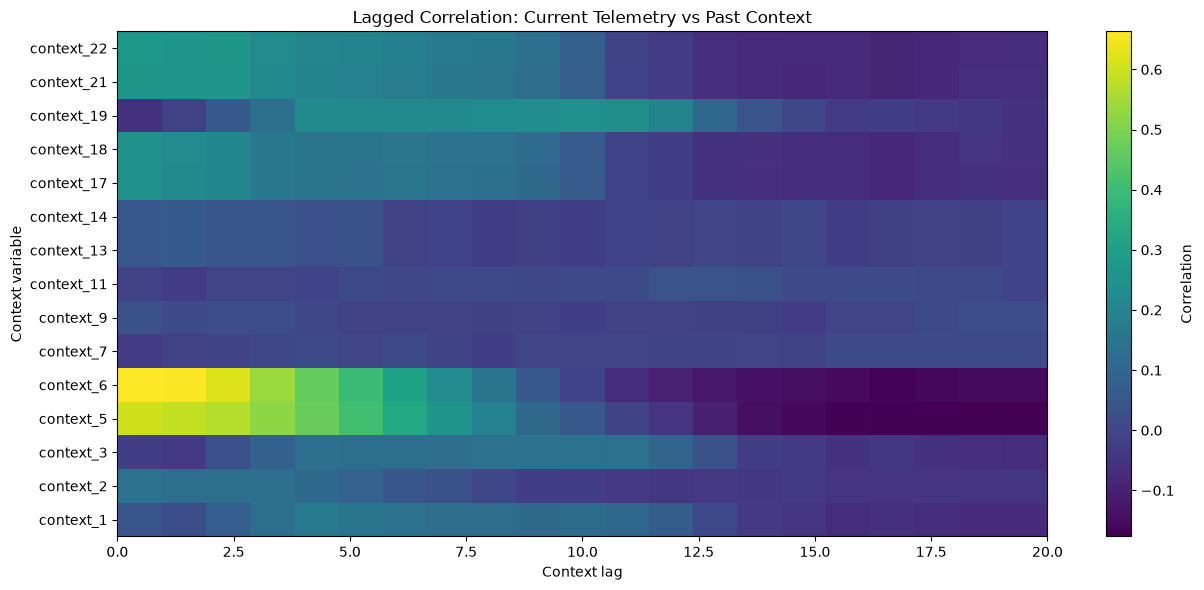

In [8]:
MAX_CONTEXT_LAG = 20

lagged_corr = pd.DataFrame(
    index=np.arange(0, MAX_CONTEXT_LAG + 1),
    columns=nonconstant_names,
    dtype=float
)

for lag in range(0, MAX_CONTEXT_LAG + 1):
    if lag == 0:
        y = train_signal
        Z = nonconstant_train_context
    else:
        y = train_signal[lag:]
        Z = nonconstant_train_context[:-lag, :]

    for j, name in enumerate(nonconstant_names):
        lagged_corr.loc[lag, name] = np.corrcoef(
            y,
            Z[:, j]
        )[0, 1]

lagged_corr.index.name = "lag"

display(lagged_corr.round(3))

fig, ax = plt.subplots(figsize=(13, 6))

image = ax.imshow(
    lagged_corr.T.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    origin="lower",
    extent=[
        0,
        MAX_CONTEXT_LAG,
        0.5,
        len(nonconstant_names) + 0.5
    ]
)

ax.set(
    title="Lagged Correlation: Current Telemetry vs Past Context",
    xlabel="Context lag",
    ylabel="Context variable"
)

ax.set_yticks(np.arange(1, len(nonconstant_names) + 1))
ax.set_yticklabels(nonconstant_names)

fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()


### Strongest lag for each context variable

In [9]:
rows = []

for name in nonconstant_names:
    series = lagged_corr[name]
    best_lag = series.abs().idxmax()

    rows.append({
        "context": name,
        "strongest_lag": int(best_lag),
        "correlation": series.loc[best_lag],
        "absolute_correlation": abs(series.loc[best_lag])
    })

strongest_lag_df = (
    pd.DataFrame(rows)
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

display(strongest_lag_df)


,context,strongest_lag,correlation,absolute_correlation
0,context_6,0,0.663332,0.663332
1,context_5,0,0.602789,0.602789
2,context_22,0,0.269912,0.269912
3,context_21,0,0.269460,0.269460
4,context_17,0,0.255216,0.255216
5,context_18,0,0.253711,0.253711
6,context_19,10,0.246029,0.246029
7,context_1,4,0.164791,0.164791
8,context_3,10,0.144506,0.144506
9,context_2,0,0.140434,0.140434


## 7. Context–context correlations

For two binary context variables, Pearson correlation is equivalent to the phi coefficient.

This is useful for spotting redundant context predictors and understanding why higher-lag ARX models may suffer from multicollinearity.


,context_1,context_2,context_3,context_5,context_6,context_7,context_9,context_11,context_13,context_14,context_17,context_18,context_19,context_21,context_22
context_1,1.000,0.411,0.842,0.409,0.023,-0.007,0.140,-0.007,0.140,0.140,-0.009,-0.008,0.616,0.160,0.135
context_2,0.411,1.000,-0.013,0.166,0.192,-0.003,-0.002,-0.003,0.342,0.342,0.042,0.043,-0.009,0.383,0.392
context_3,0.842,-0.013,1.000,0.386,-0.063,-0.006,0.076,-0.006,-0.004,-0.004,-0.029,-0.028,0.702,-0.023,-0.033
context_5,0.409,0.166,0.386,1.000,0.866,-0.016,0.025,-0.016,0.061,0.061,0.316,0.313,0.275,0.382,0.384
context_6,0.023,0.192,-0.063,0.866,1.000,-0.014,-0.010,-0.014,0.071,0.071,0.368,0.365,-0.044,0.429,0.442
context_7,-0.007,-0.003,-0.006,-0.016,-0.014,1.000,-0.001,-0.001,-0.001,-0.001,-0.006,-0.006,-0.004,-0.008,-0.007
context_9,0.140,-0.002,0.076,0.025,-0.010,-0.001,1.000,-0.001,-0.001,-0.001,-0.004,-0.004,-0.003,0.131,-0.005
context_11,-0.007,-0.003,-0.006,-0.016,-0.014,-0.001,-0.001,1.000,-0.001,-0.001,-0.006,-0.006,-0.004,-0.008,-0.007
context_13,0.140,0.342,-0.004,0.061,0.071,-0.001,-0.001,-0.001,1.000,1.000,-0.004,-0.004,-0.003,0.131,0.134
context_14,0.140,0.342,-0.004,0.061,0.071,-0.001,-0.001,-0.001,1.000,1.000,-0.004,-0.004,-0.003,0.131,0.134


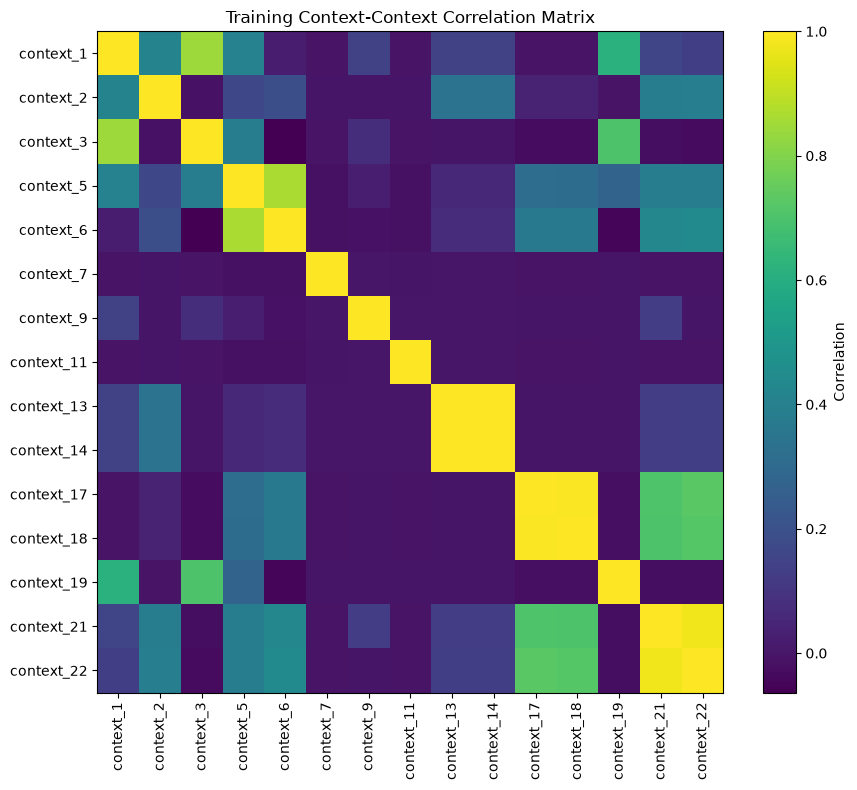

In [10]:
context_corr = pd.DataFrame(
    nonconstant_train_context,
    columns=nonconstant_names
).corr()

display(context_corr.round(3))

fig, ax = plt.subplots(figsize=(9, 8))

image = ax.imshow(
    context_corr.to_numpy(),
    aspect="auto",
    interpolation="nearest"
)

ax.set(title="Training Context-Context Correlation Matrix")

ax.set_xticks(np.arange(len(nonconstant_names)))
ax.set_xticklabels(nonconstant_names, rotation=90)

ax.set_yticks(np.arange(len(nonconstant_names)))
ax.set_yticklabels(nonconstant_names)

fig.colorbar(image, ax=ax, label="Correlation")

plt.tight_layout()
plt.show()


## 8. Highly correlated context pairs

In [11]:
PAIR_THRESHOLD = 0.70

pair_rows = []

for i in range(len(nonconstant_names)):
    for j in range(i + 1, len(nonconstant_names)):
        corr = context_corr.iloc[i, j]

        if abs(corr) >= PAIR_THRESHOLD:
            pair_rows.append({
                "context_1": nonconstant_names[i],
                "context_2": nonconstant_names[j],
                "correlation": corr,
                "absolute_correlation": abs(corr)
            })

high_corr_pairs = pd.DataFrame(pair_rows)

if len(high_corr_pairs) > 0:
    high_corr_pairs = (
        high_corr_pairs
        .sort_values("absolute_correlation", ascending=False)
        .reset_index(drop=True)
    )

display(high_corr_pairs)


,context_1,context_2,correlation,absolute_correlation
0,context_13,context_14,1.000000,1.000000
1,context_17,context_18,0.993552,0.993552
2,context_21,context_22,0.976540,0.976540
3,context_5,context_6,0.866187,0.866187
4,context_1,context_3,0.842315,0.842315
5,context_17,context_22,0.726417,0.726417
6,context_18,context_22,0.720047,0.720047
7,context_17,context_21,0.709138,0.709138
8,context_18,context_21,0.702916,0.702916
9,context_3,context_19,0.702095,0.702095


## 9. Context activity during anomaly vs normal periods

This section uses the labeled **test** anomalies only for descriptive EDA.

It should not be used to select predictors, lag orders, or detector settings.


In [12]:
anomaly_context = test_context[p1_truth, :]
normal_context = test_context[~p1_truth, :]

rows = []

for j, name in enumerate(context_names):
    anomaly_rate = np.mean(anomaly_context[:, j] != 0)
    normal_rate = np.mean(normal_context[:, j] != 0)

    rows.append({
        "context": name,
        "anomaly_active_rate": anomaly_rate,
        "normal_active_rate": normal_rate,
        "difference": anomaly_rate - normal_rate
    })

activity_df = pd.DataFrame(rows)

activity_df["absolute_difference"] = activity_df["difference"].abs()

activity_df = (
    activity_df
    .sort_values("absolute_difference", ascending=False)
    .reset_index(drop=True)
)

display(activity_df)


,context,anomaly_active_rate,normal_active_rate,difference,absolute_difference
0,context_5,0.177097,0.159144,0.017954,0.017954
1,context_6,0.139814,0.123936,0.015878,0.015878
2,context_22,0.042610,0.039850,0.002759,0.002759
3,context_12,0.002663,0.000258,0.002405,0.002405
4,context_7,0.002663,0.001290,0.001373,0.001373
5,context_11,0.002663,0.001290,0.001373,0.001373
6,context_3,0.029294,0.028115,0.001180,0.001180
7,context_2,0.007989,0.006964,0.001025,0.001025
8,context_8,0.001332,0.000387,0.000945,0.000945
9,context_17,0.029294,0.028372,0.000922,0.000922


# Suggested interpretation

For your current ARX/RF comparison, I would pay the most attention to:

- **autocorrelation of telemetry**, because it tells you how persistent the series is;
- **lagged context–telemetry correlation**, because that is directly related to whether past context may help forecast current telemetry;
- **context–context correlation**, because strong redundancy helps explain why adding many lags to OLS ARX can make the model unstable;
- **context activity inside vs outside anomaly intervals**, because P-1's anomalies are contextual.

I would treat simple correlation with the anomaly indicator as secondary, since a contextual anomaly can occur even when neither telemetry nor any one context feature has a strong marginal correlation with the label.
